#### **Gradient Boosting is an ensemble learning algorithm that builds weak learners sequentially, with each new learner attempting to correct the errors of the existing ensemble**

### **AdaBoost fixes its errors by changing sample weights (making missed data points heavier so the next tree pays more attention to them), whereas Gradient Boosting fixes its errors by changing the target values (forcing the next tree to predict the exact numerical error left over by the previous trees).**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
data = load_breast_cancer(as_frame=True)

df = data.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

df.info()

Dataset shape: (569, 31)

Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Missing values: 0

Target distribution:
target
0    212
1    357
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             5

In [5]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


### **Gradient Boosting is an ensemble learning algorithm that builds multiple weak learners sequentially and combines them into a stronger model.**

| Feature                | Random Forest                   | AdaBoost                       | Gradient Boosting           |
| ---------------------- | ------------------------------- | ------------------------------ | --------------------------- |
| Technique              | Bagging                         | Boosting                       | Boosting                    |
| Training               | Trees are generally independent | Sequential                     | Sequential                  |
| Main learning approach | Aggregate randomized trees      | Reweight difficult samples     | Fit trees to loss gradients |
| Combining predictions  | Voting or averaging             | Weighted learner predictions   | Additive model updates      |
| Scaling required       | Generally no                    | Generally no for tree learners | Generally no                |


In [8]:
gb_model = GradientBoostingClassifier(

    n_estimators=100, # Controls max no.of boosting stages 

    learning_rate=0.1,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    subsample=1.0,
    random_state=42
)

print(gb_model)

GradientBoostingClassifier(random_state=42)


In [9]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [10]:
y_pred_gb = gb_model.predict(X_test)

print("Actual values:", y_test.head(10).tolist())
print("Predicted values:", y_pred_gb[:10].tolist())

Actual values: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]
Predicted values: [0, 1, 0, 0, 0, 1, 1, 0, 0, 0]


In [11]:
print("Accuracy:", accuracy_score(y_test, y_pred_gb))

print("Precision:", precision_score(y_test, y_pred_gb))

print("Recall:", recall_score(y_test, y_pred_gb))

print("F1 Score:", f1_score(y_test, y_pred_gb))

Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231


[[38  4]
 [ 1 71]]


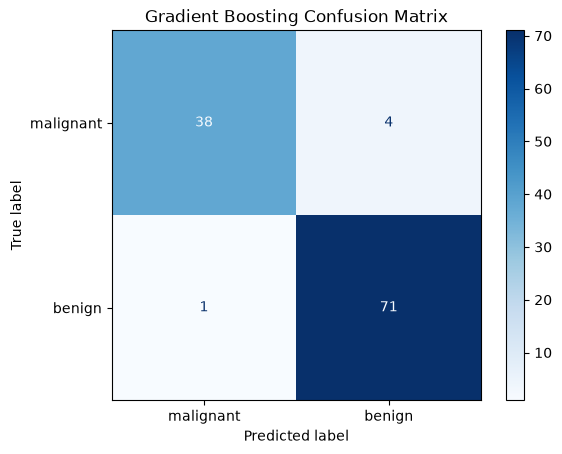

In [12]:
cm = confusion_matrix(y_test, y_pred_gb)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [13]:
print("Number of boosting stages:", gb_model.n_estimators_)
print("Number of fitted stages:", len(gb_model.estimators_))

Number of boosting stages: 100
Number of fitted stages: 100


Tree depth: 3
Number of leaves: 7


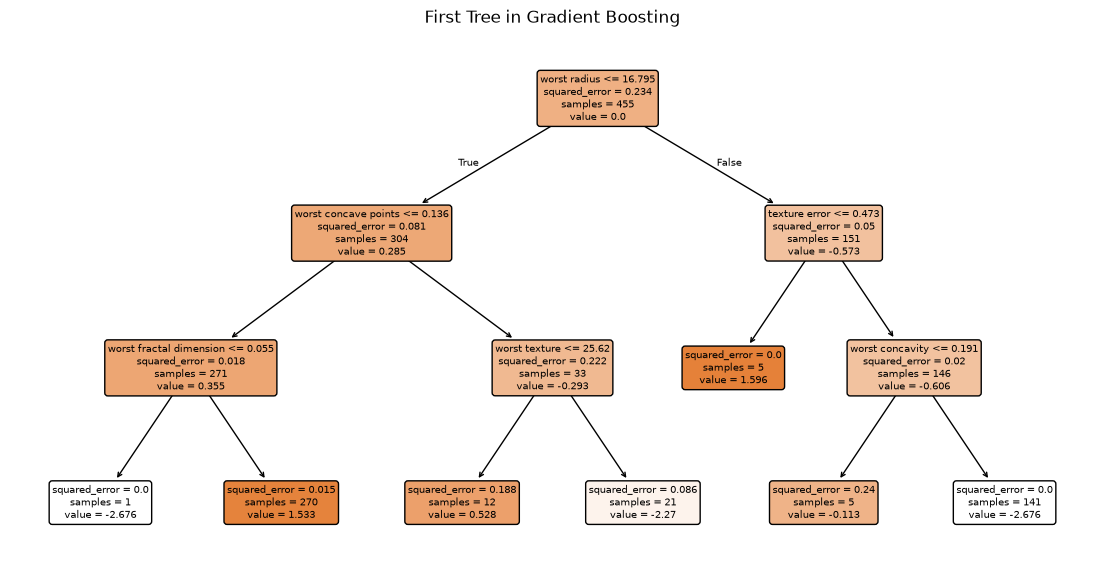

In [ ]:
from sklearn.tree import plot_tree

first_tree = gb_model.estimators_[0, 0] # Selects 1st tree from 1st boosting stage

print("Tree depth:", first_tree.get_depth())
print("Number of leaves:", first_tree.get_n_leaves())

plt.figure(figsize=(14, 7))

plot_tree(
    first_tree,
    feature_names=X.columns,
    filled=True,
    rounded=True
)

plt.title("First Tree in Gradient Boosting")
plt.show()